In [ ]:
import numpy as np 
import pandas as pd 
from tensorflow.keras.models import Sequential
import tensorflow as tf 
import matplotlib.pyplot as plt 
from tensorflow.keras.layers import(Conv2D,MaxPooling2D,Flatten,Dense)



In [16]:
from keras.utils import image_dataset_from_directory
from tensorflow.keras import layers, models

In [67]:
train_ds=tf.keras.utils.image_dataset_from_directory(
    "catdog_dataset/train",
     label_mode="int",
     
     batch_size=32,
      image_size=(256, 256),
       
)

Found 168 files belonging to 2 classes.


In [66]:
vad_ds=tf.keras.utils.image_dataset_from_directory(
    "catdog_dataset/test",
     label_mode="int",
     
     batch_size=32,
      image_size=(256, 256),
)

Found 78 files belonging to 2 classes.


In [68]:
def process(image, label):
    image=tf.cast(image/255. ,tf.float32)
    return image,label

train_ds =train_ds.map(process)
vad_ds= vad_ds.map(process)

In [69]:
model=Sequential()

In [70]:
model.add(
    Conv2D(filters=32,kernel_size=(3,3),activation="relu",input_shape=(256,256,3))
)

c:\Users\hp\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [71]:
model.add(
    MaxPooling2D(
        pool_size=(2,2),
        
    )
)

In [73]:
model.add(
    Conv2D(filters=64,kernel_size=(3,3),activation="relu")
)
model.add(
    MaxPooling2D(
        pool_size=(2,2),
        
    )
)

In [88]:
model.add(Flatten())

In [90]:
model.add(Dense(128,activation="relu"))
model.add(Dense(64,activation="relu"))
model.add(Dense(1,activation="sigmoid"))

In [89]:
model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_4 (Conv2D)               │ (None, 254, 254, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 127, 127, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 125, 125, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 62, 62, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 60, 60, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_6 (MaxPooling2D)  │ (None, 30, 30, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_2 (Flatten)             │ (None, 57600)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_15 (Dense)                │ (None, 128)            │     7,372,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_16 (Dense)                │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_17 (Dense)                │ (None, 10)             │           650 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_18 (Dense)                │ (None, 128)            │         1,408 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_19 (Dense)                │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_20 (Dense)                │ (None, 1)              │            65 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_3 (Flatten)             │ (None, 1)              │             0 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 22,343,651 (85.23 MB)

 Trainable params: 7,447,883 (28.41 MB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 14,895,768 (56.82 MB)

In [81]:
model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

In [87]:
history=model.fit(
    train_ds,
    validation_data=vad_ds,
    epochs=20
)

Epoch 1/20


c:\Users\hp\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


6/6 ━━━━━━━━━━━━━━━━━━━━ 29s 5s/step - accuracy: 0.8393 - loss: 0.5206 - val_accuracy: 0.5513 - val_loss: 0.7874
Epoch 2/20
6/6 ━━━━━━━━━━━━━━━━━━━━ 12s 2s/step - accuracy: 0.5536 - loss: 0.7703 - val_accuracy: 0.5897 - val_loss: 0.6703
Epoch 3/20
6/6 ━━━━━━━━━━━━━━━━━━━━ 21s 2s/step - accuracy: 0.8393 - loss: 0.4873 - val_accuracy: 0.5769 - val_loss: 0.7050
Epoch 4/20
6/6 ━━━━━━━━━━━━━━━━━━━━ 33s 4s/step - accuracy: 0.7500 - loss: 0.5437 - val_accuracy: 0.6282 - val_loss: 0.6605
Epoch 5/20
6/6 ━━━━━━━━━━━━━━━━━━━━ 35s 3s/step - accuracy: 0.8929 - loss: 0.3974 - val_accuracy: 0.5513 - val_loss: 0.8111
Epoch 6/20
6/6 ━━━━━━━━━━━━━━━━━━━━ 15s 2s/step - accuracy: 0.9107 - loss: 0.3185 - val_accuracy: 0.6026 - val_loss: 0.8008
Epoch 7/20
6/6 ━━━━━━━━━━━━━━━━━━━━ 15s 2s/step - accuracy: 0.9464 - loss: 0.2431 - val_accuracy: 0.6410 - val_loss: 0.8065
Epoch 8/20
6/6 ━━━━━━━━━━━━━━━━━━━━ 23s 3s/step - accuracy: 0.8988 - loss: 0.2889 - val_accuracy: 0.5000 - val_loss: 1.1759
Epoch 9/20
6/6 ━━━━

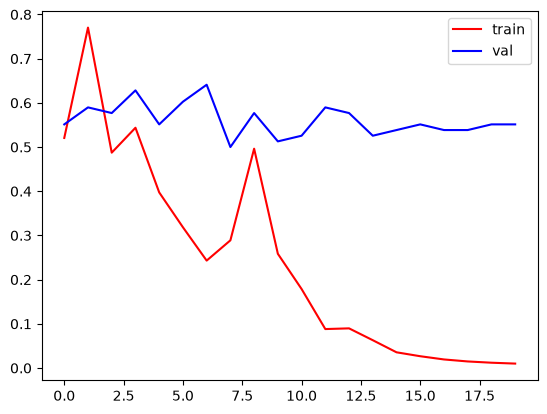

In [95]:
plt.plot(history.history['loss'],color='red',label='train')
plt.plot(history.history['val_accuracy'],color='blue',label='val')
plt.legend()
plt.show()


In [106]:
test_loss, test_accuracy = model.evaluate(
    train_ds
)

6/6 ━━━━━━━━━━━━━━━━━━━━ 3s 412ms/step - accuracy: 1.0000 - loss: 0.0090


In [112]:
print(
    "Test Accuracy:",
    test_accuracy
)

Test Accuracy: 1.0


In [124]:
prediction = model.predict(
    train_ds
)


6/6 ━━━━━━━━━━━━━━━━━━━━ 3s 426ms/step


In [125]:
predicted_class = prediction.argmax()

In [126]:
print(
    "Predicted:",
    predicted_class
)

Predicted: 12
